In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
from config import FIGURE_DIR, RAW_DIR

In [3]:
print("Raw Dataset directory:", RAW_DIR)
print("Raw Dataset Directory exists:", RAW_DIR.exists())

Raw Dataset directory: D:\Big Data Project\data\raw
Raw Dataset Directory exists: True


## Verify dataset file sizes

In [4]:
files = sorted(RAW_DIR.glob("*.csv"))

file_info = []

for file in files:
    size_mb = file.stat().st_size / (1024**2)

    file_info.append({
        "File": file.name,
        "Size (MB)": round(size_mb, 2)
    })

file_df = pd.DataFrame(file_info)

display(file_df)

print(
    "Total size (GB):",
    round(file_df["Size (MB)"].sum() / 1024, 2)
)

,File,Size (MB)
0,building_metadata.csv,0.04
1,sample_submission.csv,426.83
2,test.csv,1394.71
3,train.csv,647.18
4,weather_test.csv,14.10
5,weather_train.csv,7.10


Total size (GB): 2.43


## Inspect the energy readings

In [5]:
train_path = RAW_DIR / "train.csv"

train_sample = pd.read_csv(
    train_path,
    nrows=10
)

display(train_sample)

print("Column names:")
print(train_sample.columns.tolist())

print("\nData types:")
print(train_sample.dtypes)

,building_id,meter,timestamp,meter_reading
0,0,0,2016-01-01 00:00:00,0.0
1,1,0,2016-01-01 00:00:00,0.0
2,2,0,2016-01-01 00:00:00,0.0
3,3,0,2016-01-01 00:00:00,0.0
4,4,0,2016-01-01 00:00:00,0.0
5,5,0,2016-01-01 00:00:00,0.0
6,6,0,2016-01-01 00:00:00,0.0
7,7,0,2016-01-01 00:00:00,0.0
8,8,0,2016-01-01 00:00:00,0.0
9,9,0,2016-01-01 00:00:00,0.0


Column names:
['building_id', 'meter', 'timestamp', 'meter_reading']

Data types:
building_id        int64
meter              int64
timestamp            str
meter_reading    float64
dtype: object


## Inspect building characteristics

In [6]:
building_path = RAW_DIR / "building_metadata.csv"

buildings = pd.read_csv(building_path)

print("Shape:", buildings.shape)

display(buildings.head(10))

print("\nMissing values:")
print(buildings.isna().sum())

print("\nBuilding categories:")
print(buildings["primary_use"].value_counts())

Shape: (1449, 6)


,site_id,building_id,primary_use,square_feet,year_built,floor_count
0,0,0,Education,7432,2008.0,NaN
1,0,1,Education,2720,2004.0,NaN
2,0,2,Education,5376,1991.0,NaN
3,0,3,Education,23685,2002.0,NaN
4,0,4,Education,116607,1975.0,NaN
5,0,5,Education,8000,2000.0,NaN
6,0,6,Lodging/residential,27926,1981.0,NaN
7,0,7,Education,121074,1989.0,NaN
8,0,8,Education,60809,2003.0,NaN
9,0,9,Office,27000,2010.0,NaN



Missing values:
site_id           0
building_id       0
primary_use       0
square_feet       0
year_built      774
floor_count    1094
dtype: int64

Building categories:
primary_use
Education                        549
Office                           279
Entertainment/public assembly    184
Public services                  156
Lodging/residential              147
Other                             25
Healthcare                        23
Parking                           22
Warehouse/storage                 13
Manufacturing/industrial          12
Retail                            11
Services                          10
Technology/science                 6
Food sales and service             5
Utility                            4
Religious worship                  3
Name: count, dtype: int64


## Inspect weather observations

In [7]:
weather_path = RAW_DIR / "weather_train.csv"

weather_sample = pd.read_csv(
    weather_path,
    nrows=10
)

display(weather_sample)

print("\nColumn names:")
print(weather_sample.columns.tolist())

print("\nData types:")
print(weather_sample.dtypes)

,site_id,timestamp,air_temperature,cloud_coverage,dew_temperature,precip_depth_1_hr,sea_level_pressure,wind_direction,wind_speed
0,0,2016-01-01 00:00:00,25.0,6.0,20.0,NaN,1019.7,0.0,0.0
1,0,2016-01-01 01:00:00,24.4,NaN,21.1,-1.0,1020.2,70.0,1.5
2,0,2016-01-01 02:00:00,22.8,2.0,21.1,0.0,1020.2,0.0,0.0
3,0,2016-01-01 03:00:00,21.1,2.0,20.6,0.0,1020.1,0.0,0.0
4,0,2016-01-01 04:00:00,20.0,2.0,20.0,-1.0,1020.0,250.0,2.6
5,0,2016-01-01 05:00:00,19.4,NaN,19.4,0.0,NaN,0.0,0.0
6,0,2016-01-01 06:00:00,21.1,6.0,21.1,-1.0,1019.4,0.0,0.0
7,0,2016-01-01 07:00:00,21.1,NaN,21.1,0.0,1018.8,210.0,1.5
8,0,2016-01-01 08:00:00,20.6,NaN,20.0,0.0,1018.1,0.0,0.0
9,0,2016-01-01 09:00:00,21.1,NaN,20.6,0.0,1019.0,290.0,1.5



Column names:
['site_id', 'timestamp', 'air_temperature', 'cloud_coverage', 'dew_temperature', 'precip_depth_1_hr', 'sea_level_pressure', 'wind_direction', 'wind_speed']

Data types:
site_id                 int64
timestamp                 str
air_temperature       float64
cloud_coverage        float64
dew_temperature       float64
precip_depth_1_hr     float64
sea_level_pressure    float64
wind_direction        float64
wind_speed            float64
dtype: object


## Verify the dataset without loading it into RAM

In [8]:
import duckdb

In [9]:
con = duckdb.connect()

train_file = train_path.as_posix()

query = """
SELECT
    meter,
    COUNT(*) AS total_records,
    MIN(timestamp) AS first_timestamp,
    MAX(timestamp) AS last_timestamp,
    MIN(meter_reading) AS minimum_reading,
    MAX(meter_reading) AS maximum_reading
FROM read_csv_auto(?, header=true)
GROUP BY meter
ORDER BY meter
"""

meter_summary = con.execute(
    query,
    [train_file]
).df()

display(meter_summary)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,meter,total_records,first_timestamp,last_timestamp,minimum_reading,maximum_reading
0,0,12060910,2016-01-01,2016-12-31 23:00:00,0.0,79769.0
1,1,4182440,2016-01-01,2016-12-31 23:00:00,0.0,880374.0
2,2,2708713,2016-01-01,2016-12-31 23:00:00,0.0,21904700.0
3,3,1264037,2016-01-01,2016-12-31 23:00:00,0.0,160187.0


In [10]:
query = """
SELECT
    meter,
    COUNT(*) AS total_records,
    COUNT(DISTINCT building_id) AS unique_buildings,
    SUM(CASE WHEN meter_reading = 0 THEN 1 ELSE 0 END)
        AS zero_readings,
    ROUND(
        100.0 * SUM(CASE WHEN meter_reading = 0 THEN 1 ELSE 0 END)
        / COUNT(*), 2
    ) AS zero_percentage,
    COUNT(*) - COUNT(meter_reading) AS missing_readings,
    ROUND(AVG(meter_reading), 2) AS mean_reading,
    ROUND(MEDIAN(meter_reading), 2) AS median_reading
FROM read_csv_auto(?, header=true)
GROUP BY meter
ORDER BY meter
"""

meter_audit = con.execute(
    query,
    [train_file]
).df()

display(meter_audit)

,meter,total_records,unique_buildings,zero_readings,zero_percentage,missing_readings,mean_reading,median_reading
0,0,12060910,1413,530169.0,4.40,0,170.83,62.83
1,1,4182440,498,656504.0,15.70,0,633.36,120.49
2,2,2708713,324,346960.0,12.81,0,13882.19,257.81
3,3,1264037,145,340343.0,26.93,0,385.87,39.62


In [11]:
metadata_file = building_path.as_posix()

query = """
SELECT
    b.site_id,
    COUNT(*) AS electricity_records,
    COUNT(DISTINCT t.building_id) AS buildings,
    ROUND(AVG(t.meter_reading), 2) AS mean_reading
FROM read_csv_auto(?, header=true) AS t
JOIN read_csv_auto(?, header=true) AS b
    ON t.building_id = b.building_id
WHERE t.meter = 0
GROUP BY b.site_id
ORDER BY b.site_id
"""

site_audit = con.execute(
    query,
    [train_file, metadata_file]
).df()

display(site_audit)

,site_id,electricity_records,buildings,mean_reading
0,0,908409,105,226.53
1,1,447982,51,162.37
2,2,1184512,135,152.62
3,3,2370097,274,125.92
4,4,746746,91,181.09
5,5,781776,89,31.30
6,6,315436,36,176.28
7,7,104784,12,2041.81
8,8,567915,70,65.74
9,9,1068748,122,179.99


# Investigating electricity consumption

## Investigate the distribution of electricity readings

In [12]:
query = """
SELECT
    MIN(meter_reading) AS minimum,
    QUANTILE_CONT(meter_reading, 0.25) AS q1,
    MEDIAN(meter_reading) AS median,
    QUANTILE_CONT(meter_reading, 0.75) AS q3,
    QUANTILE_CONT(meter_reading, 0.95) AS p95,
    QUANTILE_CONT(meter_reading, 0.99) AS p99,
    MAX(meter_reading) AS maximum
FROM read_csv_auto(?, header=true)
WHERE meter = 0
"""

electricity_distribution = con.execute(
    query,
    [train_file]
).df()

display(electricity_distribution)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,minimum,q1,median,q3,p95,p99,maximum
0,0.0,19.5,62.8319,170.075,647.40955,1629.61,79769.0


## Examine zero readings by site

In [13]:
query = """
SELECT
    b.site_id,
    COUNT(*) AS total_records,
    SUM(
        CASE WHEN t.meter_reading = 0
        THEN 1 ELSE 0 END
    ) AS zero_readings,
    ROUND(
        100.0 * SUM(
            CASE WHEN t.meter_reading = 0
            THEN 1 ELSE 0 END
        ) / COUNT(*), 2
    ) AS zero_percentage
FROM read_csv_auto(?, header=true) AS t
JOIN read_csv_auto(?, header=true) AS b
    ON t.building_id = b.building_id
WHERE t.meter = 0
GROUP BY b.site_id
ORDER BY zero_percentage DESC
"""

zero_by_site = con.execute(
    query,
    [train_file, metadata_file]
).df()

display(zero_by_site)

,site_id,total_records,zero_readings,zero_percentage
0,0,908409,346426.0,38.14
1,7,104784,12632.0,12.06
2,8,567915,26582.0,4.68
3,14,890768,40538.0,4.55
4,9,1068748,44786.0,4.19
5,13,1236660,19874.0,1.61
6,15,841195,12428.0,1.48
7,5,781776,8023.0,1.03
8,2,1184512,9944.0,0.84
9,4,746746,3879.0,0.52


## Identify buildings with the highest average consumption

In [14]:
query = """
SELECT
    t.building_id,
    b.site_id,
    b.primary_use,
    b.square_feet,
    COUNT(*) AS observations,
    ROUND(AVG(t.meter_reading), 2) AS mean_reading,
    ROUND(MAX(t.meter_reading), 2) AS max_reading
FROM read_csv_auto(?, header=true) AS t
JOIN read_csv_auto(?, header=true) AS b
    ON t.building_id = b.building_id
WHERE t.meter = 0
GROUP BY
    t.building_id,
    b.site_id,
    b.primary_use,
    b.square_feet
ORDER BY mean_reading DESC
LIMIT 15
"""

top_buildings = con.execute(
    query,
    [train_file, metadata_file]
).df()

display(top_buildings)

,building_id,site_id,primary_use,square_feet,observations,mean_reading,max_reading
0,801,7,Education,484376,8781,4650.17,7296.45
1,794,7,Education,731945,8782,4125.03,6013.39
2,803,7,Education,182986,8189,3613.62,5914.19
3,1088,13,Education,287594,8769,3430.59,8894.00
4,797,7,Education,764237,8781,3106.07,5246.31
5,223,2,Education,261188,8782,2496.68,3193.57
6,795,7,Education,387500,8780,2429.26,5399.10
7,375,3,Office,850354,8782,2048.10,3095.44
8,1168,13,Office,577101,8528,1963.89,44336.50
9,799,7,Education,527431,8781,1945.10,17502.10


## Generate our first distribution visualization

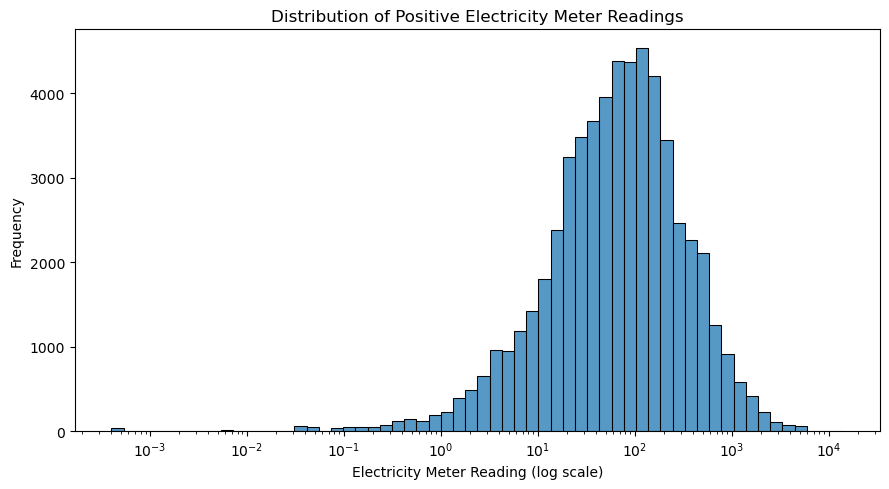

In [15]:
query = """
SELECT meter_reading
FROM read_csv_auto(?, header=true)
WHERE meter = 0
  AND meter_reading > 0
USING SAMPLE 100000 ROWS
"""

sample_df = con.execute(
    query,
    [train_file]
).df()

plt.figure(figsize=(9, 5))

sns.histplot(
    data=sample_df,
    x="meter_reading",
    bins=60,
    log_scale=(True, False)
)

plt.title("Distribution of Positive Electricity Meter Readings")
plt.xlabel("Electricity Meter Reading (log scale)")
plt.ylabel("Frequency")

plt.tight_layout()
#plt.savefig(FIGURE_DIR / "distribution_postive_electricity_meter_readings.png", bbox_inches="tight")
plt.show()

# Investigate Site 0 and zero-reading patterns

## Which buildings contribute most to Site 0's zero readings?

In [16]:
query = """
SELECT
    t.building_id,
    b.primary_use,
    b.square_feet,
    COUNT(*) AS total_records,
    COUNT(*) FILTER (
        WHERE t.meter_reading = 0
    ) AS zero_readings,
    ROUND(
        100.0 * COUNT(*) FILTER (
            WHERE t.meter_reading = 0
        ) / COUNT(*), 2
    ) AS zero_percentage,
    ROUND(AVG(t.meter_reading), 2) AS mean_reading
FROM read_csv_auto(?, header=true) AS t
JOIN read_csv_auto(?, header=true) AS b
    ON t.building_id = b.building_id
WHERE t.meter = 0
  AND b.site_id = 0
GROUP BY
    t.building_id,
    b.primary_use,
    b.square_feet
ORDER BY zero_readings DESC
LIMIT 20
"""

site0_buildings = con.execute(
    query,
    [train_file, metadata_file]
).df()

display(site0_buildings)

,building_id,primary_use,square_feet,total_records,zero_readings,zero_percentage,mean_reading
0,45,Retail,15304,8783,4356,49.60,1.65
1,69,Parking,387638,8784,3627,41.29,61.45
2,71,Parking,387638,8784,3389,38.58,86.55
3,59,Entertainment/public assembly,81337,8784,3383,38.51,107.72
4,86,Education,10932,8784,3380,38.48,53.54
5,82,Office,10743,8784,3379,38.47,33.18
6,7,Education,121074,8784,3378,38.46,350.33
7,68,Parking,487433,8784,3378,38.46,87.86
8,55,Office,16726,8784,3378,38.46,71.22
9,102,Office,15876,8784,3378,38.46,80.14


## Are zero readings concentrated in particular months?

In [17]:
query = """
SELECT
    STRFTIME(t.timestamp, '%Y-%m') AS month,
    COUNT(*) AS total_records,
    COUNT(*) FILTER (
        WHERE t.meter_reading = 0
    ) AS zero_readings,
    ROUND(
        100.0 * COUNT(*) FILTER (
            WHERE t.meter_reading = 0
        ) / COUNT(*), 2
    ) AS zero_percentage
FROM read_csv_auto(?, header=true) AS t
JOIN read_csv_auto(?, header=true) AS b
    ON t.building_id = b.building_id
WHERE t.meter = 0
  AND b.site_id = 0
GROUP BY STRFTIME(t.timestamp, '%Y-%m')
ORDER BY month
"""

site0_monthly = con.execute(
    query,
    [train_file, metadata_file]
).df()

display(site0_monthly)

,month,total_records,zero_readings,zero_percentage
0,2016-01,76431,75224,98.42
1,2016-02,71567,70467,98.46
2,2016-03,76745,76347,99.48
3,2016-04,74373,74024,99.53
4,2016-05,76430,48850,63.91
5,2016-06,74303,952,1.28
6,2016-07,76719,131,0.17
7,2016-08,77182,60,0.08
8,2016-09,74880,28,0.04
9,2016-10,77374,57,0.07


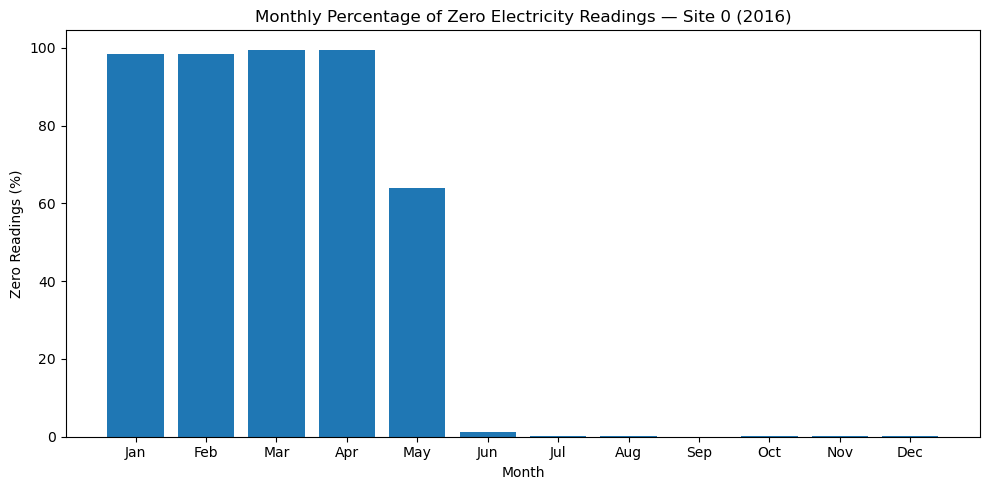

In [18]:
month_dates = pd.to_datetime(site0_monthly["month"], format="%Y-%m")
year = month_dates.dt.year.iloc[0]

plt.figure(figsize=(10, 5))

plt.bar(
    site0_monthly["month"],
    site0_monthly["zero_percentage"]
)

plt.title(f"Monthly Percentage of Zero Electricity Readings — Site 0 ({year})")
plt.xlabel("Month")
plt.ylabel("Zero Readings (%)")
plt.xticks(site0_monthly["month"], month_dates.dt.strftime("%b"))

plt.tight_layout()
#plt.savefig(FIGURE_DIR / "monthly_percentage_of_zero_electricity_readings_site0.png", bbox_inches="tight")
plt.show()